In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import corner
import json

from torch.utils.data import random_split
from glasflow.nflows import distributions, flows

from v1_1_pmssm_model.load_data import load_data
from v1_1_pmssm_model.norm_flow import *

In [ ]:
# We are only doing analysis in this notebook so cpu is enough
device = "cpu"
torch.set_num_threads(4)   # match the cgroup quota; check with: cat /sys/fs/cgroup/cpu.max

In [5]:
# Provide the JSON file path that contains the hyperparameters
training_index = 1
json_file_path = f"/u/yinya/workspace/multi_modal_pMSSM/v1.1_pMSSM_model/normalizing_flow/hyperparams/training_{training_index}.json"

# Load the JSON file
with open(json_file_path, "r", encoding="utf-8") as f:
    hparam_data = json.load(f)

# Very unnecessary default values to avoid undefined warnings in compiler
num_flow_steps = 10
hidden_dim = 512
num_transform_blocks = 2
batch_norm = False
base_transform_type = "rq-coupling"
data_fraction = 1.0
train_fraction = 0.8
data_folder = "/ptmp/yinya/gen_flat_28346825/ntuples"
num_bins = 8
tail_bound = 3.0

# List the hyperparameters needed from the file
hparam_list = ['num_flow_steps', 'hidden_dim', 'num_transform_blocks', 'batch_norm', 'base_transform_type', 'data_fraction',
                'train_fraction', 'data_folder', 'num_bins', 'tail_bound']

# Create variables from the JSON keys
for key in hparam_list:
    if key in hparam_data.keys():  # Ensure it's a valid Python variable name
        globals()[key] = hparam_data[key]
    else:
        print(f"Variable not found: {key}")

In [6]:
parameters, mo_omega, parameters_mean, parameters_std, parameters_standardized, theory_param, theory_param_nonconst = load_data(data_folder=data_folder, data_fraction=data_fraction)

mo_omega_dataset = pMSSM_Dataset(parameters_standardized, mo_omega, device)

num_samples = len(mo_omega_dataset)
num_train = int(round(train_fraction * num_samples))
num_test = num_samples - num_train
generator1 = torch.Generator().manual_seed(42)
train_dataset, test_dataset = random_split(mo_omega_dataset, [num_train, num_test], generator=generator1)

print(f"Test sample size: {num_test}")

---Load pMSSM dataset---
Loading files: 250/250
Loaded 250 files from ['/ptmp/yinya/gen_flat_28346825/ntuples']
Total samples: 2000000
Samples after filter on relic density: 1565111
Test sample size: 313022


### Data loading and preprocessing

In [7]:
print(f"Shape of the parameters: {parameters_standardized.shape}")

Shape of the parameters: (1565111, 12)


Inspect data distribution of the `pMSSM_dataset`.

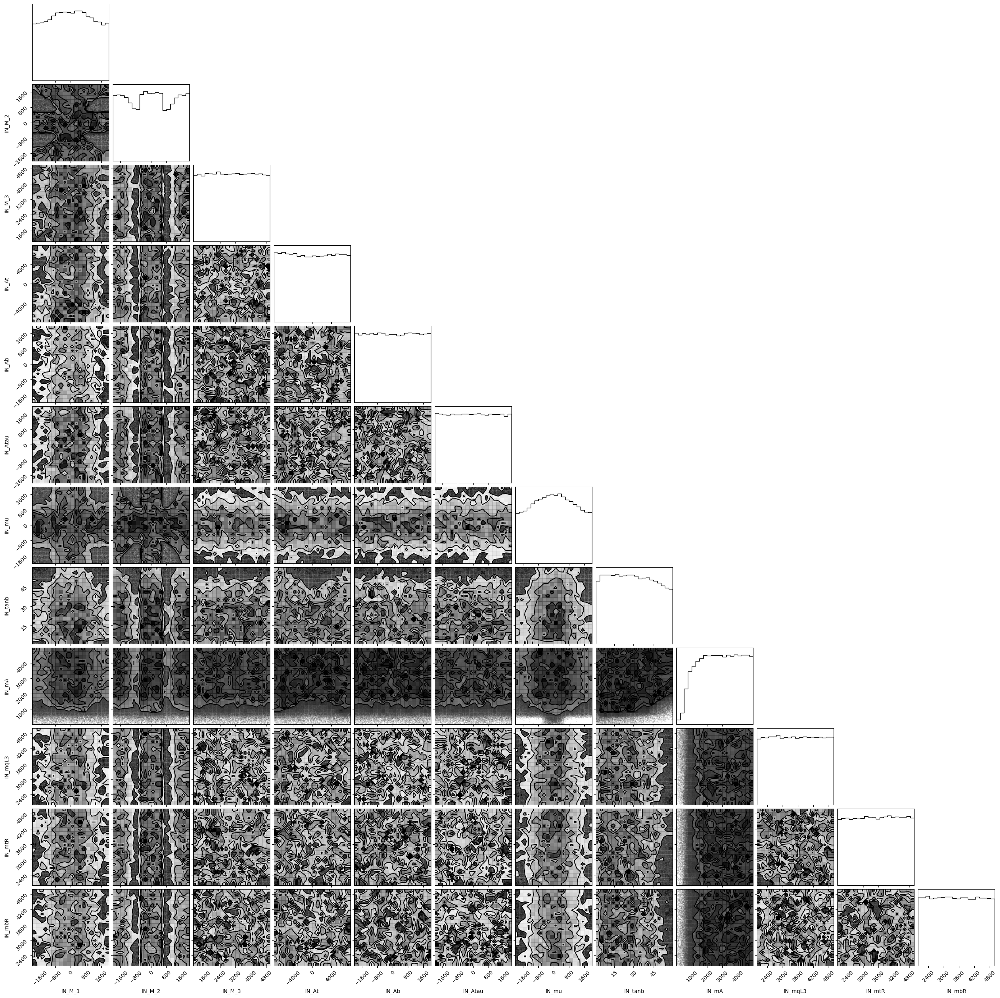

In [ ]:
# Show only 1/10 of total samples to save time
corner.corner(parameters[::10,:], labels=theory_param_nonconst)
# corner.corner(parameters, labels=theory_param_nonconst)
plt.show()

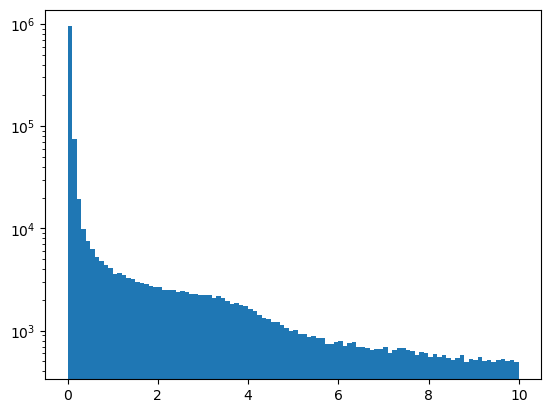

In [9]:
plt.hist(mo_omega[np.argwhere(mo_omega<10)[:,0]], bins=100, log=True)
plt.show()

### Conditional Normalizing Flow
We use the `glasflow` library. It is a wrapper for [`nflows`](https://github.com/bayesiains/nflows), which implements different flow types (e.g. autoregressive flows and coupling flows) and transforms (e.g. rational-quadratic splines).


The entire flow model consists of a standard normal base distribution, followed by the flow transform.

In [10]:
base_transform_kwargs = {
    "base_transform_type": base_transform_type,
    "hidden_dim": hidden_dim,
    "num_transform_blocks": num_transform_blocks,
    "batch_norm": batch_norm,
}
if base_transform_type == "rq-coupling":
    base_transform_kwargs["num_bins"] = num_bins
    base_transform_kwargs["tail_bound"] = tail_bound

transform = create_transform(num_flow_steps = num_flow_steps,
                             param_dim = np.shape(parameters_standardized)[-1],
                             context_dim = np.shape(mo_omega)[-1], #np.shape(data) instead of data.shape to avoid error by one-dim array
                             base_transform_kwargs = base_transform_kwargs)

base_distribution = distributions.StandardNormal(shape=[parameters_standardized.shape[-1]])

model = flows.Flow(transform, base_distribution)
model = model.to(device)

### Load Weights into the Model

In [22]:
weights_path = f"checkpoints/training_{training_index}_latest.pt"
training_info = torch.load(weights_path, map_location=torch.device('cpu'))
print(training_info.keys())
model.load_state_dict(training_info['model_state_dict'])

/tmp/ipykernel_83702/2986936689.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  training_info = torch.load(weights_path, map_location=torch.device('cpu'))


dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_test_loss', 'train_history', 'test_history'])


<All keys matched successfully>

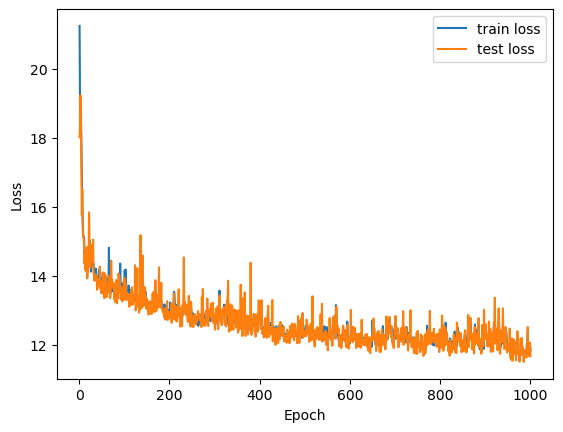

In [18]:
training_info['best_test_loss']
epochs = np.arange(1, len(training_info['train_history']) + 1)
plt.plot(epochs, training_info['train_history'], '-', label = 'train loss')
plt.plot(epochs, training_info['test_history'], '-', label = 'test loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### Evaluate the result and visualize posteriors

In [23]:
model = model.eval()

#### Negative Log Likelihood

In [ ]:
def compute_nll(dataset, model, batch_size=8192):
    if isinstance(dataset, torch.utils.data.Subset):
        parent, idx = dataset.dataset, dataset.indices
        params, obs = parent.parameters[idx], parent.observables[idx]
    else:
        params, obs = dataset.parameters, dataset.observables

    total = torch.zeros((), dtype=torch.float64)   # float64 accumulator
    with torch.no_grad():
        for i in range(0, len(params), batch_size):
            total -= model.log_prob(params[i:i+batch_size],
                                    obs[i:i+batch_size]).double().sum()
    return (total / len(params)).item()

In [27]:
# compute_nll(mo_omega_dataset, model)
compute_nll(train_dataset, model)

11.663403279868234

#### Choose data points randomly

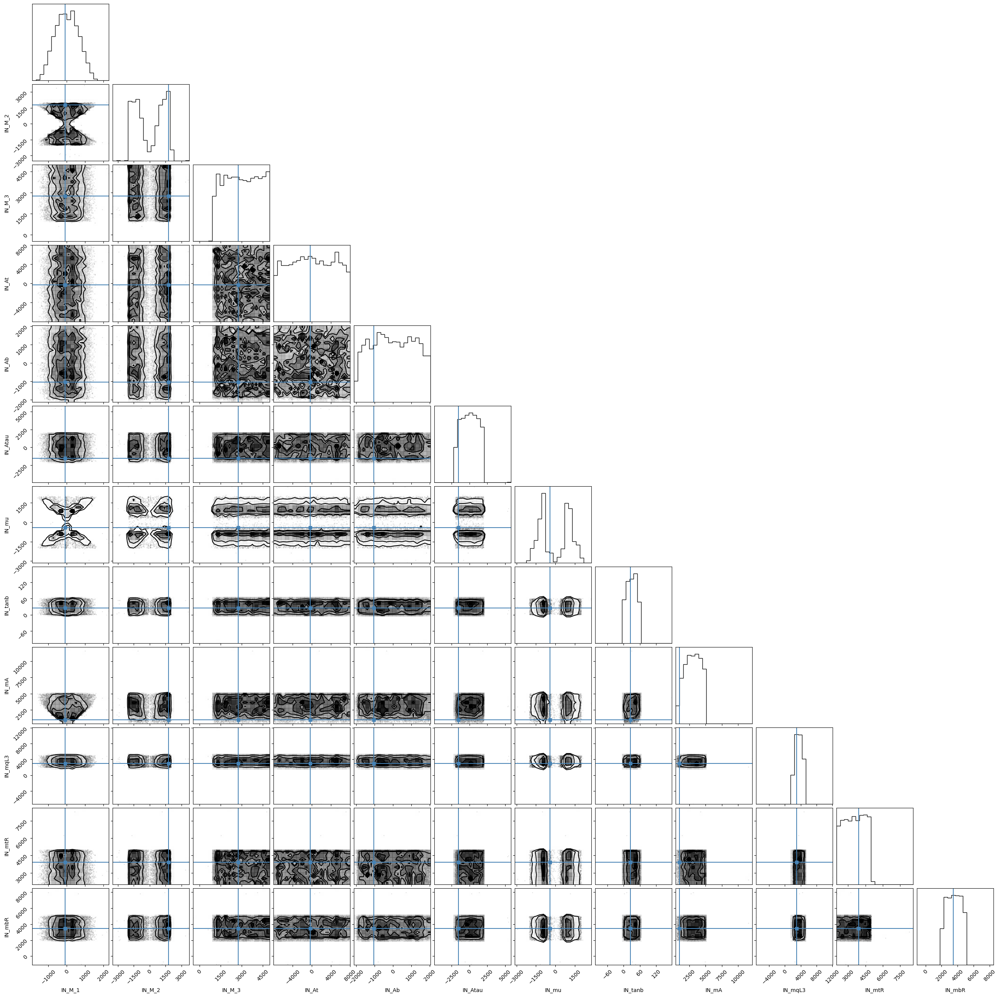

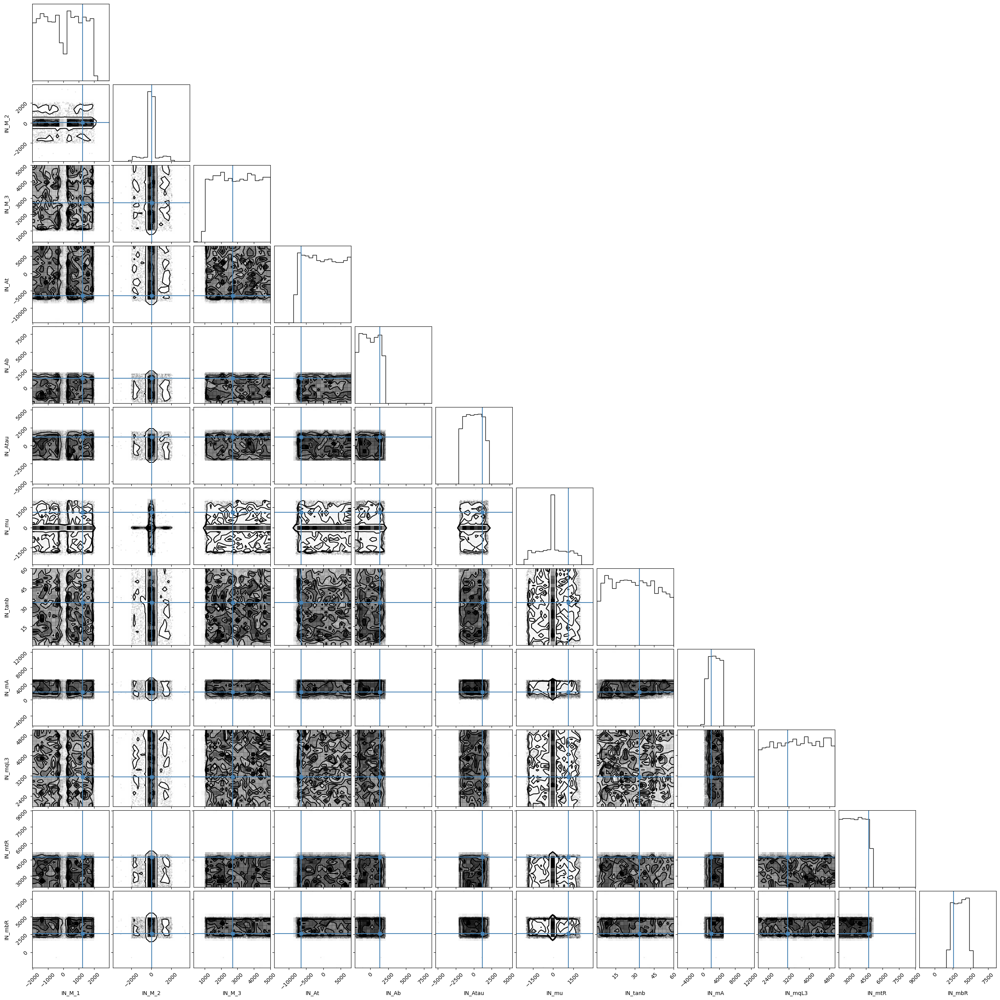

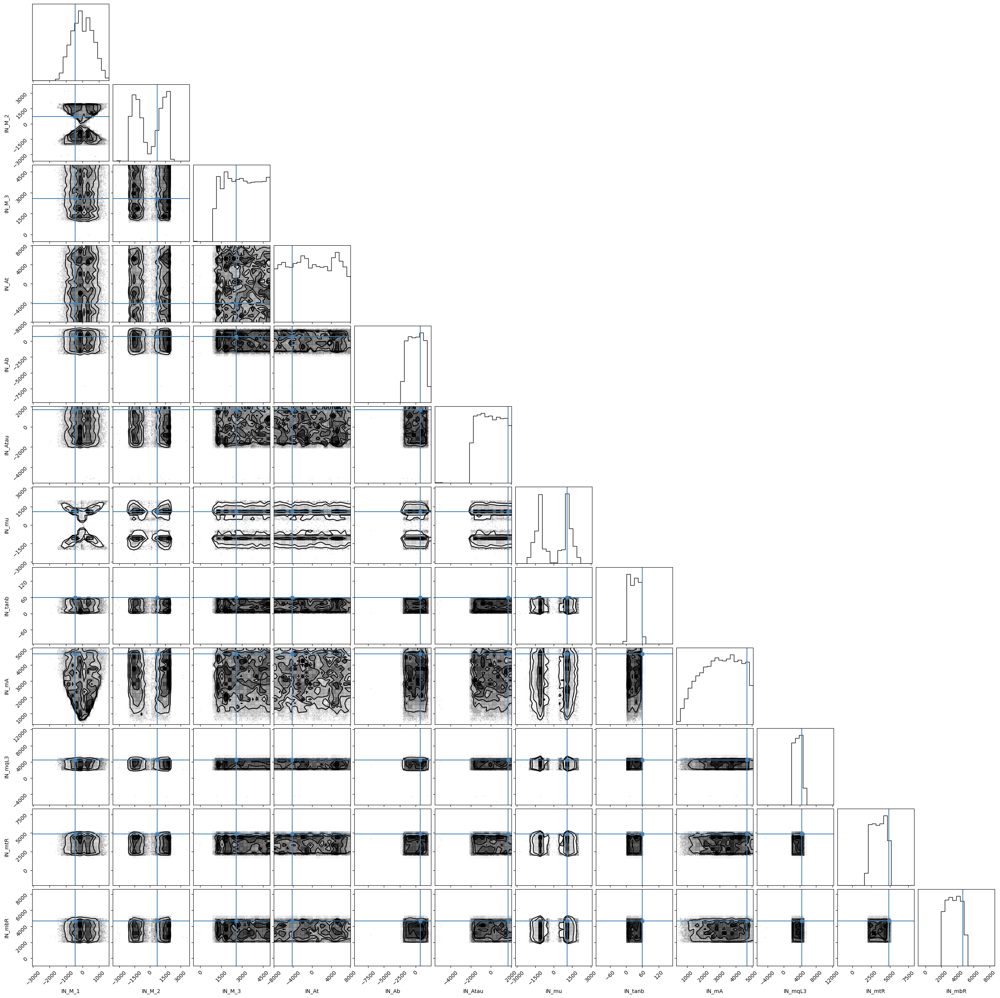

In [28]:
num_posteriors = 3
num_eval_samples = 10_000

# model = model.eval()

for n in range(num_posteriors):

    with torch.no_grad():
    
        test_x, test_y = test_dataset[n]
    
        # Sample the posterior
        test_x = test_x.expand(num_eval_samples, *test_x.shape)
        pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()
    
        # Undo the standardization
        pred_samples = parameters_std * pred_samples + parameters_mean
        truth = parameters_std * test_y.cpu().numpy() + parameters_mean
    
        # Plot
        corner.corner(pred_samples, truths=truth, labels=theory_param_nonconst)
        plt.show()

#### Use data points closest to chosen observables

In [47]:
target = 10
idx_cl = (test_dataset.dataset.observables[test_dataset.indices] - target).abs().argmin()
print(idx_cl)
test_dataset[idx_cl]

tensor(20698)


(tensor([10.]),
 tensor([-0.9348, -1.1065,  0.0141,  0.0749, -0.5504,  0.9035, -1.7249, -1.6541,
         -0.2605,  1.2646, -0.2833, -1.6382]))

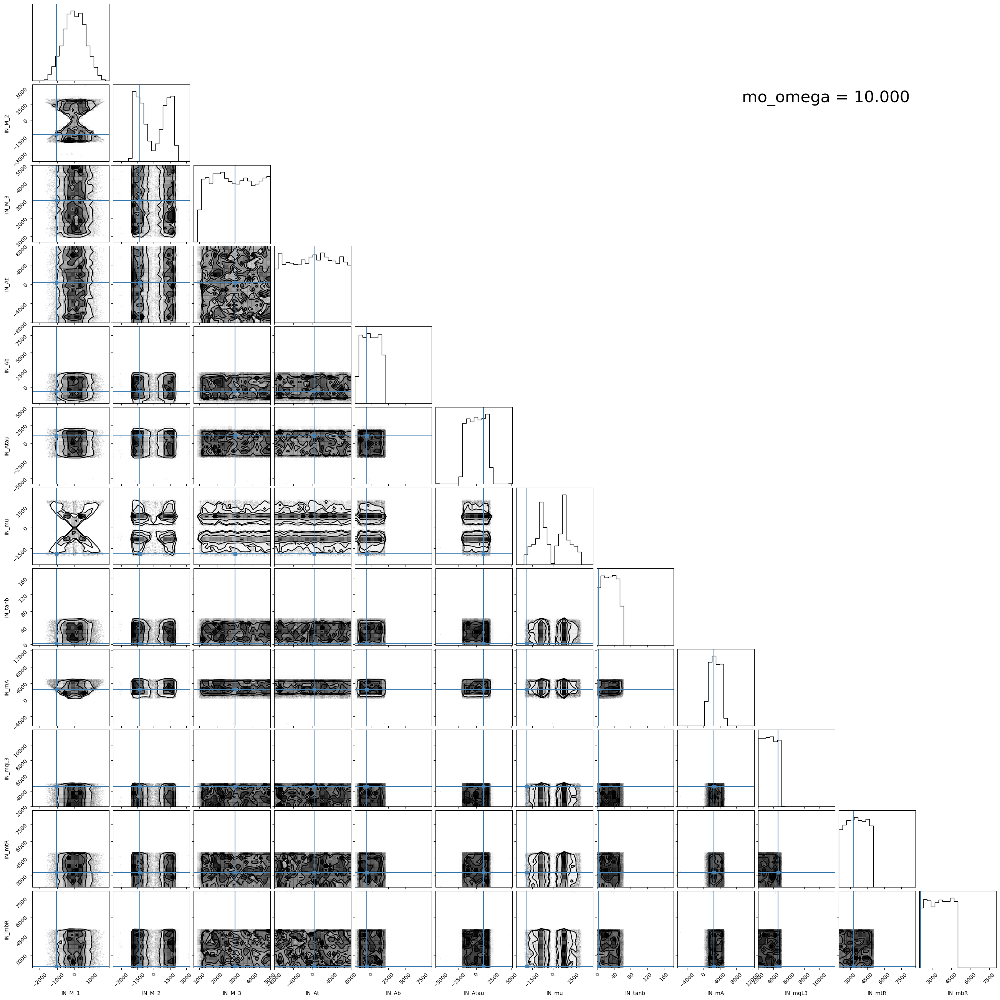

In [48]:
with torch.no_grad():

    test_x, test_y = test_dataset[idx_cl]

    # Sample the posterior
    test_x = test_x.expand(10000, *test_x.shape)
    pred_samples = model.sample(1, test_x).squeeze(1).cpu().numpy()

    # Undo the standardization
    pred_samples = parameters_std * pred_samples + parameters_mean
    truth = parameters_std * test_y.cpu().numpy() + parameters_mean

    # Plot
    fig = corner.corner(
        pred_samples,
        truths=truth,
        labels=theory_param_nonconst
    )

    fig.text(
        0.9, 0.9,                 # x, y in figure coordinates
        f"mo_omega = {test_x[0].cpu().numpy()[0]:.3f}",
        ha="right",
        va="top",
        fontsize=30,
        # bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
    )

    plt.show()

#### Dynamic visualisation

In [42]:
from PIL import Image

# lower_bound = 0
# upper_bound = 0.5
# step_size = 0.025

# input_folder = f"figures/training_{training_index}/pred_pngs/{lower_bound}_{upper_bound}_{step_size}"
input_folder = f"figures/training_{training_index}/pred_pngs/default"

if not os.path.exists(input_folder):
    os.makedirs(input_folder)

##### PNG Generation

In [43]:
# x_list = np.arange(lower_bound, upper_bound+step_size, step_size)
# x_list = np.concatenate(np.arange(0, 0.5, 0.025), np.arange(0.5, 10.5, 0.5)) # default
x_list = np.arange(1, 10.5, 0.5)
ranges = np.outer(parameters_std, [-4,4]) + parameters_mean[:, None]

for x_value in x_list:
    with torch.no_grad():
        
        x_value = torch.as_tensor(x_value, device=device, dtype=torch.float32)

        if x_value.ndim == 0:
            x_value = x_value.unsqueeze(0)
        
        # Sample the posterior
        x_value = x_value.expand(10000, *x_value.shape)
        pred_samples = model.sample(1, x_value).squeeze(1).cpu().numpy()

        # Undo the standardization
        pred_samples = parameters_std * pred_samples + parameters_mean

        # Plot
        fig = corner.corner(
            pred_samples,
            labels=theory_param_nonconst,
            range=ranges
        )

        fig.text(
            0.9, 0.9,                 # x, y in figure coordinates
            f"mo_omega = {x_value[0].cpu().numpy()[0]:.3f}",
            ha="right",
            va="top",
            fontsize=30,
            # bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
        )

        plt.savefig(os.path.join(input_folder, f"model_{training_index}_mo_omega_{x_value[0].cpu().numpy()[0]:.3f}.png"))
        plt.close(fig)

Load Data

In [37]:
import glob
import re

def extract_value_one_path(path):
    # get the last number/float in the file names
    filename = os.path.basename(path)
    matches = re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", filename)
    return float(matches[-1])

def extract_value(input_folder):
    paths = glob.glob(os.path.join(input_folder, "*.png"))
    values = np.array([extract_value_one_path(p) for p in paths])

    # sort
    order = np.argsort(values)
    values = values[order]
    paths = [paths[i] for i in order]

    return values, paths

##### GIF Generation

In [44]:
def pngs_to_gif(
    input_folder,
    output_gif="animation.gif",
    fps=10,
):
    """
    Convert PNG images in a folder into a GIF.

    Parameters
    ----------
    input_folder : str
        Folder containing PNG files.
    output_gif : str
        Output GIF filename.
    fps : float
        Frames per second.
    """

    _, paths = extract_value(input_folder)

    frames = [Image.open(f).convert("RGBA") for f in paths]

    duration_ms = int(1000 / fps)

    frames[0].save(
        output_gif,
        save_all=True,
        append_images=frames[1:],
        duration=duration_ms,
        loop=0,
        disposal=2,
    )

    print(f"GIF saved: {output_gif}")
    print(f"Frames: {len(frames)}")
    print(f"FPS: {fps}")
    
pngs_to_gif(
    input_folder=input_folder,
    # output_gif=os.path.join(input_folder, f"model_{training_index}_{lower_bound}_{upper_bound}_{step_size}.gif"),
    output_gif=os.path.join(input_folder, f"model_{training_index}_default.gif"),
    fps=5,
)

GIF saved: figures/training_1/pred_pngs/default/model_1_default.gif
Frames: 40
FPS: 5


##### Interactive

In [99]:
from IPython.display import display
import ipywidgets as widgets


values, paths = extract_value(input_folder)

# ----------------------------
# exact-value lookup
# ----------------------------
def get_image(v):
    idx = np.where(values == v)[0][0]
    return paths[idx], v

# ----------------------------
# widget: ONLY allowed values
# ----------------------------
slider = widgets.SelectionSlider(
    options=[(f"{v:.3f}", v) for v in values],
    value=values[0],
    description="Omega",
    continuous_update=True
)

out = widgets.Output()

def update(change):
    with out:
        out.clear_output(wait=True)
        path, v = get_image(change["new"])
        print(f"Omega: {v}")
        display(Image.open(path))

slider.observe(update, names="value")

# initial display
update({"new": values[0]})

display(slider, out)

SelectionSlider(description='Omega', options=(('0.000', 0.0), ('0.025', 0.025), ('0.050', 0.05), ('0.075', 0.0…

Output()